In [30]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# Heat equation PINN

The aim of this project is to create a PINN which is able to solve the heat equation. We will do 2 main things in the project:
1. Forward problem: solve the heat equation with a known diffusivity constant
2. Inverse problem: infer an unknown diffusivity from observations 

Before we begin, we will introduce the governing law defining the problem. See Part 3, Chapter 8 of the notes for the theory. The heat equation IVP is given by:

$$ u_t - \kappa u_{xx}=0, \hspace{3mm} (x,t)\in (0,1)\times[0,1] $$

with boundary and initial conditions given by:

$$ u(0,t)=u(1,t)=0, \hspace{3mm} u(x,0) = \sin(\pi x) $$

For this model we are going to use the following architecture:

$$ 2 \rightarrow 32 \rightarrow 32 \rightarrow 1 $$

with $\tanh$ hidden activation functions and affine layers for the outputs.

In [31]:
torch.set_default_dtype(torch.float64)

### Creating collocation points. Will create points inside region and on the boundaries

# A few reused tensors:
t_bound = torch.linspace(0, 1, steps=64) # Creates 64 evenly spaced points in [0,1]
zeros_64 = torch.zeros(64) # Creates a [64,] tensor of all 0's
ones_64 = torch.ones(64) # Creates a [64,] tensor of all 1's


## Inside the region bounded by (0,1)X[0,1]. The points [x,t]
# We will create 32 x points and 16 t points so that 32x16=512.
# NOTE: The choice of 32 space and 16 time points is arbitrary. We could have easily chosen 16 space and 32 time
# or any other divisors of 512. Changing the numbers of these, changes the fineness with which we measure that
# coordinate.

# Interior midpoints on each axis
x_f = (torch.arange(32, dtype=torch.float64) + 0.5) / 32 # Dividing by 32 normalises
t_f = (torch.arange(16, dtype=torch.float64) + 0.5) / 16 # Dividing by 16 normalises
# Every combination of position and time
Z_f = torch.cartesian_prod(x_f, t_f).requires_grad_(True)


## Initial condition: 64 evenly spaced positions at t=0. The points [x,0]
x_i = torch.linspace(0, 1, steps=64 + 2)[1:-1] # Adding 2 steps and [1:-1] ensures endpoints
                                                                    # are excluded
Z_i = torch.stack((x_i,zeros_64),dim=1)


## Boundary condition x=0: 64 evenly spaced points. The points [0,t]
Z_left = torch.stack((zeros_64, t_bound), dim=1)


## Boundary condition x=1: 64 evenly spaced points. The points [1,t]
Z_right = torch.stack((ones_64, t_bound), dim=1)

## Residuals and losses

It is evident that the IVP contains 4 valuable pieces of information:
1. The PDE (the heat equation)
2. Initial condition ($t=0$)
3. Left boundary condition ($x=0$)
4. Right boundary condition ($x=1$)

As such, we are going to have 4 resdiuals and 4 loss components. Let $u(x,t)$ be the solution to the heat equation. Then for our model prediction $u_\theta(x,t)$, the differential equation residual is given by:

$$ r_\theta(x,t) = \partial_tu_\theta(x,t)-\kappa\partial_{xx}u_\theta(x,t) - \left(u_t-\kappa u_{xx}\right) $$

But since the heat equation equals 0, this simplifies as:

$$ r_\theta(x,t) = \partial_tu_\theta(x,t)-\kappa\partial_{xx}u_\theta(x,t) $$

Since we take the MSE of for our loss, the differential equation loss is given by:

\begin{equation}\tag{1} \mathcal{L}_f(x,t) = \text{mean}(r_\theta(x,t)^2) \end{equation}

Recalling, the residuals for an initial condition $t=0$ is given by:

$$ r_i(x,t) = u_\theta(x,0) - u(x,0) $$ 

and noticing that $u(x,0)=\sin(\pi x)$ we get:

\begin{equation}\tag{2}\mathcal{L}_i(x,0) = \text{mean}(\left(u_\theta(x,0)-\sin(\pi x)\right)^2) \end{equation}

The boundary conditions are given by $u(0,t)=u(1,t)=0$ so that we easily yield:

\begin{equation}\tag{3}\mathcal{L}_{left}(0,t) = \text{mean}((u_\theta(0,t)^2) \end{equation}
\begin{equation}\tag{4}\mathcal{L}_{right}(1,t) = \text{mean}(u_\theta(1,t)^2) \end{equation}

As such the total solution error loss is given by the weighted sum of these losses:

\begin{equation}\label{5} \mathcal{L} = \lambda_f\mathcal{L}+\lambda_i\mathcal{L}_i+\lambda_{left}\mathcal{L}_{left}+\lambda_{right}\mathcal{L}_{right}\end{equation}

The next cell encodes the functions defining these losses.

In [32]:
## Differential-equation residual function
def res_eq(model, Z, kappa=0.1):
    u = model(Z)
    
    # First differentiation
    u_1 = torch.autograd.grad(
        outputs = u,
        inputs = Z,
        grad_outputs = torch.ones_like(u),
        create_graph = True)[0]
    
    # Extracting \partial_t u and \partial_x u
    u_t = u_1[:, 1:2]
    u_x = u_1[:, 0:1]
    
    # Second differentiation
    u_2 = torch.autograd.grad(
        outputs = u_x,
        inputs = Z,
        grad_outputs = torch.ones_like(u_x),
        create_graph = True)[0]
    
    # Extracting \partial_xx u
    
    u_xx = u_2[:, 0:1]
    
    return u_t - kappa * u_xx

## Differential equation loss
def loss_eq(model, Z, kappa=0.1):
    
    res = res_eq(model, Z, kappa=kappa)
    
    return torch.mean(res**2)

## Initial condition loss

def loss_i(model, Z):
    u = model(Z)
    x_i = Z[:, 0:1]
    target_i = torch.sin(torch.pi * x_i)
    
    return torch.mean((u-target_i)**2)

## Left and right boundary condition loss

def loss_bdry(model, Z):
    u = model(Z)
    return torch.mean(u**2)

In [39]:
## Neural network architecture

class Heat_PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        return self.network(x)
    
def heateq_pinn(Z_f, Z_i, Z_left, Z_right, epochs=3000, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    model = Heat_PINN()

    params = tuple(model.parameters())
    optimiser = torch.optim.Adam(params, lr)

    history = {
        "equation": [],
        "initial": [],
        "left": [],
        "right": [],
        "total": [],
    }

    for epoch in range(epochs):
        model.train()
        optimiser.zero_grad()
        # Calculate losses
        L_f = loss_eq(model, Z_f)
        L_i = loss_i(model, Z_i)
        L_left = loss_bdry(model, Z_left)
        L_right = loss_bdry(model, Z_right)
        # Total loss
        loss = L_f + L_i + L_left + L_right
        loss.backward(inputs=params)
        optimiser.step()
        history["equation"].append(L_f.item())
        history["initial"].append(L_i.item())
        history["left"].append(L_left.item())
        history["right"].append(L_right.item())
        history["total"].append(loss.item())

    return model, history

## Model evaluation

To evaluate the model, we are going to do the usual, test outside the collocation points, compare with the true function $u(x,t) = e^{-\kappa\pi^2t}\sin(\pi x)$, and plot the spatial profiles at various $t$ values. 

MSE: tensor(4.6375e-07) , E_max: tensor(0.0044) , E_rel: tensor(0.0015)


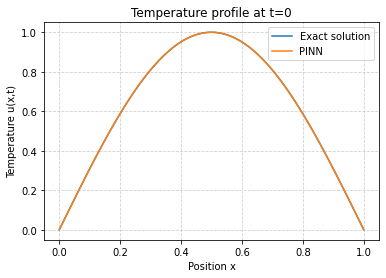

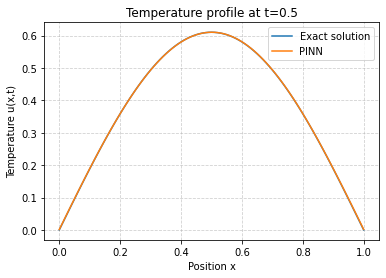

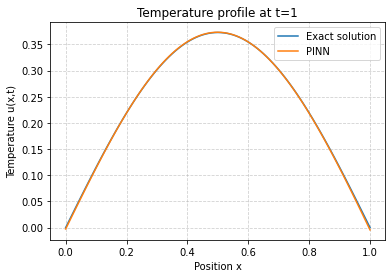

In [45]:
## Code generated from GenAI for testing ##

x_eval = torch.linspace(0.0, 1.0, 101)
t_eval = torch.linspace(0.0, 1.0, 101)
Z_eval = torch.cartesian_prod(x_eval, t_eval)

model.eval()
with torch.no_grad():
    u_eval = model(Z_eval)

x = Z_eval[:, 0:1]
t = Z_eval[:, 1:2]
u_exact = torch.exp(-0.1 * torch.pi**2 * t) * torch.sin(torch.pi * x)

## Code copied from Project 3 ##

# Signed solution error
solerrors = u_eval-u_exact

# MSE error
MSE = torch.mean(solerrors**2)

# Maximum absolute sampled error
E_max = torch.max(torch.abs(solerrors))

# Discrete relative L2 error
E_rel = torch.sqrt(torch.sum(solerrors**2))/torch.sqrt(torch.sum(u_exact**2))

print("MSE: "+str(MSE)+" , E_max: "+str(E_max)+" , E_rel: "+str(E_rel))

## Profile plots at t=0,0.5,1 ##

# Reshaping prediction and exact values to easily extract data for plotting
U_pred = u_eval.reshape(101, 101)
U_exact = u_exact.reshape(101, 101) 

# Code generated by GenAI for plotting
for j in (0, 50, 100):
    time = t_eval[j].item()

    plt.figure()
    plt.plot(x_eval, U_exact[:, j], label="Exact solution")
    plt.plot(x_eval, U_pred[:, j], label="PINN")

    plt.title(f"Temperature profile at t={time:g}")
    plt.xlabel("Position x")
    plt.ylabel("Temperature u(x,t)")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.show()

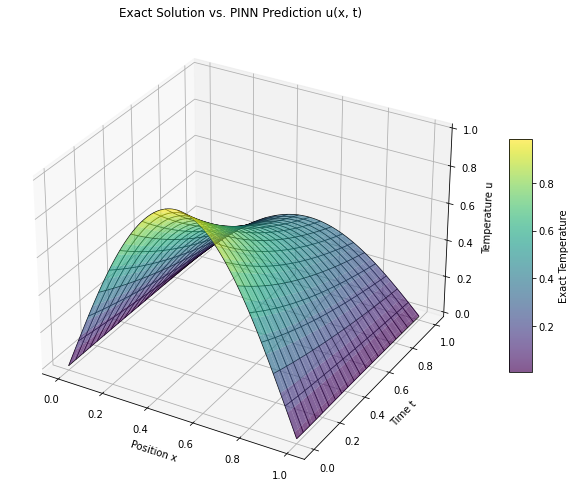

In [50]:
## Code generated from GenAI to display the model's output in a 3D surface plot

import matplotlib.pyplot as plt
import numpy as np

# Convert tensors to NumPy arrays safely
x_np = x_eval.detach().cpu().numpy().squeeze() if hasattr(x_eval, "detach") else np.asarray(x_eval).squeeze()
t_np = t_eval.detach().cpu().numpy().squeeze() if hasattr(t_eval, "detach") else np.asarray(t_eval).squeeze()
U_pred_np = U_pred.detach().cpu().numpy() if hasattr(U_pred, "detach") else np.asarray(U_pred)
U_exact_np = U_exact.detach().cpu().numpy() if hasattr(U_exact, "detach") else np.asarray(U_exact)

# Create 2D coordinate grids aligned with (101, 101)
X, T = np.meshgrid(x_np, t_np, indexing="ij")

# Create single 3D plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

# 1. Plot Exact Solution as a semi-transparent surface
surf = ax.plot_surface(
    X, T, U_exact_np,
    cmap="viridis",
    alpha=0.65,
    edgecolor="none",
    label="Exact Solution"
)

# 2. Overlay PINN Prediction as a sparse wireframe mesh
wire = ax.plot_wireframe(
    X, T, U_pred_np,
    color="black",
    rstride=5,  # Plot every 5th grid line for clarity
    cstride=5,
    linewidth=0.8,
    label="PINN Prediction"
)

# Formatting and labels
ax.set_title("Exact Solution vs. PINN Prediction u(x, t)")
ax.set_xlabel("Position x")
ax.set_ylabel("Time t")
ax.set_zlabel("Temperature u")
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label="Exact Temperature")

plt.tight_layout()
plt.show()

## Outcome

It is very clear that the model does a very good job of solving the heat equation. This can be seen from the very small MSE solution error as well as the clear overlay of the PINN model on the true solutionn plots. This is inc